# 02 V2 — Causal YOLO17 → Pose13 [13,4], Quality + Export

CPU-only, no YOLO rerun. No future leakage; train/inference feature parity.

## 1 — Cấu hình và khóa nguồn CPU

In [ ]:
from pathlib import Path
import os,sys,json,zipfile,io,hashlib,tempfile,shutil
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
DRIVE_ROOT = Path('/content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu')
ROOT = Path(os.environ['POSEFORGE_ROOT']).expanduser() if os.environ.get('POSEFORGE_ROOT') else (
    DRIVE_ROOT if DRIVE_ROOT.is_dir() else next(
        (p for p in (Path.cwd(),*Path.cwd().parents) if (p/'notebooks').is_dir() and (p/'shared').is_dir()), Path.cwd()))
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))

from shared.dataset_pipeline import scan_raw_zip, file_sha256, COCO13
from shared.pose_training import dataset_output_root, refresh_review_zip, usable_mask, LABELS
from shared.pose_features import CausalPoseNormalizer, FEATURE_VERSION, FEATURE_SHAPE, CONFIDENCE_THRESHOLD

RAW_ZIP = Path(os.environ.get('POSEFORGE_ZIP', ROOT/'raw_dataset_zip/clean_raw_14_person_11n_pt_v001.zip'))
SEED = 302
VAL_PEOPLE = ['TDUY','DGD']
TEST_PEOPLE = ['TRUONG']
assert RAW_ZIP.is_file(),f'Missing {RAW_ZIP}'
SOURCE_SHA = file_sha256(RAW_ZIP)
BASE = dataset_output_root(ROOT,SOURCE_SHA)
BASE.mkdir(parents=True,exist_ok=True)
RAW_REPORT = BASE/'raw'
PROCESSED_REPORT = BASE/'processed'

def stage_zip(source, sha):
    if not Path('/content').is_dir() or not str(source.resolve()).startswith('/content/drive/'):
        return source
    dst=Path('/content')/f'poseforge_{sha[:12]}.zip'
    if not dst.is_file() or file_sha256(dst) != sha:
        with source.open('rb') as f, dst.open('wb') as o, tqdm(total=source.stat().st_size,unit='B',unit_scale=True,desc='Stage ZIP') as p:
            while (chunk:=f.read(4*1024*1024)):
                o.write(chunk);p.update(len(chunk))
    assert file_sha256(dst)==sha
    return dst

LOCAL_ZIP=stage_zip(RAW_ZIP,SOURCE_SHA)
print('ROOT:',ROOT,'\nDATASET:',RAW_ZIP.name,'\nSHA256:',SOURCE_SHA)

assert (RAW_REPORT/'split_manifest.json').is_file(),'Run Notebook 01 V2 first'
split_info=json.loads((RAW_REPORT/'split_manifest.json').read_text())
assert split_info['source_zip_sha256']==SOURCE_SHA
assert split_info['test_people']==sorted(TEST_PEOPLE)
assert split_info['validation_people']==sorted(VAL_PEOPLE)
catalog=pd.read_csv(RAW_REPORT/'raw_catalog.csv')
split_df=pd.read_csv(RAW_REPORT/'split_manifest.csv')
assert set(catalog.clip_id)==set(split_df.clip_id)

Mounted at /content/drive


Stage ZIP:   0%|          | 0.00/528M [00:00<?, ?B/s]

ROOT: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu 
DATASET: clean_raw_14_person_11n_pt_v001.zip 
SHA256: 41774c321098e08e1103a63cd5b64e31a3a6d7e293fff30472a6cebdad919384


## 2 — Transform YOLO17 → 13×4 causal features
Mỗi clip-camera/segment khởi tạo normalizer mới. Frame thiếu pose giữ trong NPZ nhưng không được dùng cho supervised training.

In [ ]:
STAGING_ROOT = Path(tempfile.mkdtemp(prefix='poseforge_features_'))
FEATURES = STAGING_ROOT / 'features'
FEATURES.mkdir(parents=True, exist_ok=True)

clip_rows = []
frame_rows = []

with zipfile.ZipFile(LOCAL_ZIP) as z:
    prefix = next(
        n[:-len('labels.csv')]
        for n in z.namelist()
        if n.endswith('Real_Posture_Dataset/labels.csv')
    )
    splits = split_df.set_index('clip_id')['split'].to_dict()

    for row in tqdm(
        catalog.itertuples(index=False),
        total=len(catalog),
        desc='Causal normalization',
        unit='clip',
    ):
        norm = CausalPoseNormalizer(
            confidence_threshold=CONFIDENCE_THRESHOLD,
            ema_alpha=.25,
        )

        xs = []
        raws = []
        index = []
        widths = []
        heights = []
        relative_ms = []
        centers = []
        scales = []

        with z.open(prefix + row.raw_member) as f:
            for line in f:
                if not line.strip():
                    continue

                item = json.loads(line)
                k = (
                    np.asarray(item['keypoints'], dtype='float32')
                    if item.get('keypoints') is not None
                    else None
                )

                if k is not None:
                    assert k.shape == (17, 3) and np.isfinite(k).all()

                w, h = int(item['width']), int(item['height'])
                frame_id = int(item['frame_index'])
                assert frame_id == len(index)

                x, center, scale = norm.transform(k, w, h, backend='yolo')

                xs.append(x)
                raws.append(
                    k if k is not None else np.zeros((17, 3), dtype='float32')
                )
                index.append(frame_id)
                widths.append(w)
                heights.append(h)
                relative_ms.append(
                    float(item['relative_ms'])
                    if item.get('relative_ms') is not None
                    else np.nan
                )
                centers.append(center)
                scales.append(scale)

                frame_rows.append(
                    dict(
                        clip_id=row.clip_id,
                        person_id=row.person_id,
                        label=int(row.label),
                        camera_id=row.camera_id,
                        split=splits[row.clip_id],
                        frame_index=frame_id,
                        source_frame_index=int(row.source_frame_start) + frame_id,
                        source_group_id=row.source_group_id,
                        valid13_count=int(x[:, 3].sum()),
                        usable=int(x[:, 3].sum() >= 4),
                        pose_detected=int(k is not None),
                    )
                )

        assert len(xs) == int(row.frames)
        x = np.stack(xs).astype('float32')
        assert np.isfinite(x).all() and x.shape == (int(row.frames), 13, 4)

        np.savez_compressed(
            FEATURES / f'{row.clip_id}.npz',
            x=x,
            raw17=np.stack(raws),
            frame_index=np.array(index, dtype='int32'),
            relative_ms=np.array(relative_ms),
            center_px=np.stack(centers),
            scale_px=np.array(scales),
            width=np.array(widths),
            height=np.array(heights),
        )

        clip_rows.append(
            dict(
                clip_id=row.clip_id,
                person_id=row.person_id,
                label=int(row.label),
                camera_id=row.camera_id,
                session_id=row.session_id,
                take_id=row.take_id,
                source_take_id=row.source_take_id,
                source_group_id=row.source_group_id,
                source_frame_start=int(row.source_frame_start),
                source_segment=int(row.source_segment),
                split=splits[row.clip_id],
                frames=int(row.frames),
                usable_frames=int(usable_mask(x).sum()),
                feature_path=f'features/{row.clip_id}.npz',
            )
        )

index_df = pd.DataFrame(clip_rows)
frame_df = pd.DataFrame(frame_rows)

assert len(index_df) == 206 and len(frame_df) == 21996
assert set(index_df.split) == {'train', 'val', 'test'}
assert index_df.clip_id.is_unique and (frame_df.valid13_count.between(0, 13)).all()

print(
    'Frames:', len(frame_df),
    'usable >=4 joints:', int(frame_df.usable.sum()),
    'excluded supervised:', int((frame_df.usable == 0).sum()),
)

Causal normalization:   0%|          | 0/206 [00:00<?, ?clip/s]

Frames: 21996 usable >=4 joints: 21987 excluded supervised: 9


## 3 — Full NPZ checks and causal parity (all clips)
Không đưa test data vào quyết định normalization; parity chỉ kiểm tra invariant code.

In [ ]:
for row in tqdm(index_df.itertuples(index=False),total=len(index_df),desc='Validate features',unit='clip'):
    with np.load(STAGING_ROOT/row.feature_path, allow_pickle=False) as z:
        x = z['x']
        raw = z['raw17']
        w = z['width']
        h = z['height']

        assert x.shape==(row.frames,13,4) and raw.shape==(row.frames,17,3)
        assert np.isfinite(x).all() and np.isin(x[:,:,3],(0,1)).all()
        assert np.all(x[:,:,:2][x[:,:,3]==0]==0)
        assert int(usable_mask(x).sum())==row.usable_frames

        norm=CausalPoseNormalizer()
        regen=np.stack([norm.transform((None if not np.any(k) else k),int(ww),int(hh))[0]
                        for k,ww,hh in zip(raw,w,h)])
        
        np.testing.assert_allclose(x,regen,rtol=0,atol=1e-6)

        prefix_size=min(12,row.frames)
        norm=CausalPoseNormalizer()
        causal=np.stack([norm.transform((None if not np.any(k) else k),int(ww),int(hh))[0]
                         for k,ww,hh in zip(raw[:prefix_size],w[:prefix_size],h[:prefix_size])])
        
        np.testing.assert_allclose(x[:prefix_size],causal,rtol=0,atol=1e-6)
        
print('[PASS] Causal and feature parity all clips')

Validate features:   0%|          | 0/206 [00:00<?, ?clip/s]

[PASS] Causal and feature parity all clips


## 4 — Processed train-only EDA

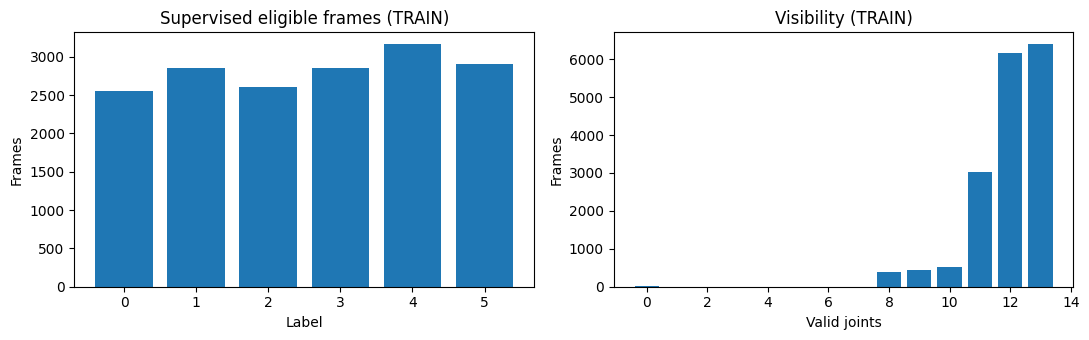

,split,label,frames,usable,avg_valid
0,test,0,144,144,12.965278
1,test,1,140,140,12.385714
2,test,2,129,129,10.356589
3,test,3,146,146,11.897260
4,test,4,128,128,11.500000
5,test,5,154,154,12.870130
6,train,0,2560,2560,12.576562
7,train,1,2851,2851,12.268327
8,train,2,2614,2605,10.715379
9,train,3,2856,2856,12.208333


In [ ]:
import matplotlib.pyplot as plt

CHARTS = PROCESSED_REPORT / 'charts'
CHARTS.mkdir(parents=True, exist_ok=True)

train = frame_df[frame_df.split == 'train']

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

# Chart 1: number of usable training frames per label
a = (
    train.groupby('label')
    .usable.agg(['sum', 'count'])
    .reindex(LABELS)
)

ax[0].bar(a.index, a['sum'])
ax[0].set(
    title='Supervised eligible frames (TRAIN)',
    xlabel='Label',
    ylabel='Frames',
)

# Chart 2: number of training frames with 0..13 valid joints
ax[1].bar(
    range(14),
    train.valid13_count.value_counts().reindex(range(14), fill_value=0),
)
ax[1].set(
    title='Visibility (TRAIN)',
    xlabel='Valid joints',
    ylabel='Frames',
)

fig.tight_layout()
fig.savefig(CHARTS / '01_usable_train.png', dpi=140)
plt.show()
plt.close(fig)

# Summary table by split and label
display(
    frame_df.groupby(['split', 'label'])
    .agg(
        frames=('frame_index', 'size'),
        usable=('usable', 'sum'),
        avg_valid=('valid13_count', 'mean'),
    )
    .reset_index()
)


## 5 — Portable processed ZIP, feature contract và review ZIP

In [ ]:
# Only one portable feature ZIP is persisted; temporary per-clip NPZs are removed.

# 1. Export clip-level, frame-level, and split metadata.
index_df.to_csv(STAGING_ROOT / 'index.csv', index=False)
frame_df.to_csv(
    STAGING_ROOT / 'frame_quality.csv.gz',
    index=False,
    compression='gzip',
)
split_df.to_csv(STAGING_ROOT / 'split_manifest.csv', index=False)

(STAGING_ROOT / 'split_manifest.json').write_text(
    json.dumps(split_info, indent=2)
)

# 2. Record the exact feature schema and normalization contract.
contract = dict(
    version=FEATURE_VERSION,
    extractor='yolo11n-pose.pt',
    joints=COCO13,
    channels=['x_norm', 'y_norm', 'confidence', 'valid_mask'],
    shape_per_frame=[13, 4],
    flatten_dim=52,
    confidence_threshold=CONFIDENCE_THRESHOLD,
    ema_alpha=.25,
    normalization='causal shoulder center and EMA scale; reset each clip/segment',
    state_scope='one person / one camera / one segment',
    missing_policy='zero xy/conf/mask, discard <4 valid for supervised',
    source_zip_sha256=SOURCE_SHA,
    split_strategy=split_info['strategy'],
)

(STAGING_ROOT / 'feature_contract.json').write_text(
    json.dumps(contract, indent=2)
)

# 3. Summarize exported data and count frames by split.
summary = dict(
    source_zip_sha256=SOURCE_SHA,
    clips=int(len(index_df)),
    frames=int(len(frame_df)),
    eligible_supervised=int(frame_df.usable.sum()),
    missing_or_insufficient=int((frame_df.usable == 0).sum()),
    splits={
        s: int((frame_df.split == s).sum())
        for s in ('train', 'val', 'test')
    },
)

(STAGING_ROOT / 'processed_summary.json').write_text(
    json.dumps(summary, indent=2)
)

# 4. Compute per-NPZ SHA256 checksums for integrity verification.
(STAGING_ROOT / 'checksums.sha256').write_text(
    ''.join(
        f'{file_sha256(f)}  {f.relative_to(STAGING_ROOT)}\n'
        for f in sorted(FEATURES.glob('*.npz'))
    )
)

# 5. Build the portable ZIP in a temporary target, then verify it.
processed_zip = PROCESSED_REPORT / 'pose13_features.zip'
processed_zip.parent.mkdir(parents=True, exist_ok=True)

tmp = processed_zip.with_suffix('.zip.tmp')

with zipfile.ZipFile(tmp, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as z:
    for p in sorted(STAGING_ROOT.rglob('*')):
        if p.is_file():
            z.write(
                p,
                'poseforge_pose13_v2/' + str(p.relative_to(STAGING_ROOT))
            )

with zipfile.ZipFile(tmp) as z:
    assert z.testzip() is None

# 6. Publish the verified ZIP, save a summary, and clean up staging.
tmp.replace(processed_zip)

(PROCESSED_REPORT / 'summary.json').write_text(
    json.dumps(summary, indent=2)
)

shutil.rmtree(STAGING_ROOT)

# 7. Update the review artifact and print the final paths.
review = refresh_review_zip(BASE)

print('[PASS] Notebook02 | features:', processed_zip, '| REVIEW:', review)


[PASS] Notebook02 | features: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/processed/pose13_features.zip | REVIEW: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/review.zip
